<a href="https://colab.research.google.com/github/yuhui-0611/Unstructured-Data-Analysis/blob/main/UDA_Project_feature_crop_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
traditional_features = pd.read_csv("/content/drive/MyDrive/UDA-Project/UDA_final dataset/traditional_features.csv")
shorts_labeled_final = pd.read_csv("/content/drive/MyDrive/UDA-Project/UDA_final dataset/shorts_labeled_final.csv")

# STEP 1. 데이터 불러오기 및 결합

In [3]:
traditional_features = pd.read_csv(
    "/content/drive/MyDrive/UDA-Project/UDA_final dataset/traditional_features_crop.csv",
    dtype={"video_id": str}
)

shorts_labeled_final = pd.read_csv(
    "/content/drive/MyDrive/UDA-Project/UDA_final dataset/shorts_labeled_final.csv",
    dtype={"video_id": str}
)

# video_id 기준 데이터 결합
trad_eda = shorts_labeled_final.merge(
    traditional_features,
    on="video_id",
    how="inner",
    validate="one_to_one"
)

print("Traditional 특징 데이터:", traditional_features.shape)
print("메타데이터:", shorts_labeled_final.shape)
print("EDA 통합 데이터:", trad_eda.shape)

assert len(trad_eda) == 1270, "영상 누락 확인"

Traditional 특징 데이터: (1270, 9)
메타데이터: (1270, 28)
EDA 통합 데이터: (1270, 36)


# STEP 2. 분석에 사용할 컬럼 확인

In [4]:
# Traditional 특징 컬럼
trad_cols = [
    col for col in traditional_features.columns
    if col.startswith("trad_")
]

# 주요 분석 변수
analysis_cols = [
    "video_id",
    "drama_name",
    "channel",
    "duration_sec",
    "days_since_upload",
    "z_in_group",
    "pct_in_group"
] + trad_cols

print("Traditional 특징:", trad_cols)

display(trad_eda[analysis_cols].head())

Traditional 특징: ['trad_brightness_mean', 'trad_brightness_std', 'trad_frame_diff_mean', 'trad_cut_count', 'trad_cut_frequency', 'trad_motion_mean', 'trad_motion_std', 'trad_motion_max']


,video_id,drama_name,channel,duration_sec,days_since_upload,z_in_group,pct_in_group,trad_brightness_mean,trad_brightness_std,trad_frame_diff_mean,trad_cut_count,trad_cut_frequency,trad_motion_mean,trad_motion_std,trad_motion_max
0,NQt0VkR9q_0,김씨 표류기,1분 샤샤샥,46.0,1124.820338,1.764644,1.0,84.957044,23.546954,52.477872,16,0.347826,4.150951,1.794800,7.245910
1,ExRxa0wD3j4,김씨 표류기,1분 샤샤샥,43.0,1123.819551,-0.697115,0.2,98.402386,30.812635,58.393560,19,0.441860,3.836146,1.736497,8.213974
2,86EflpUcel0,김씨 표류기,1분 샤샤샥,20.0,1119.812699,-0.300633,0.6,106.074581,21.427340,53.290364,5,0.250000,3.869496,2.329291,9.645676
3,EN2QjA52vwE,김씨 표류기,1분 샤샤샥,28.0,1117.813012,-0.471814,0.4,82.136237,25.033265,59.197910,18,0.642857,4.494586,1.914783,8.117878
4,GRajxajB8aA,김씨 표류기,1분 샤샤샥,28.0,1116.823348,-0.295083,0.8,78.335862,22.034147,50.913715,14,0.500000,3.484713,1.846010,9.269723


# STEP 3. Traditional 특징의 분포 및 이상치 확인(EDA)

## Traditional 특징 기초 통계 확인

In [5]:
# Traditional 특징 8개 기초 통계
display(
    trad_eda[trad_cols].describe().T.round(3)
)

,count,mean,std,min,25%,50%,75%,max
trad_brightness_mean,1270.0,77.622,26.350,24.050,57.286,77.934,95.260,166.248
trad_brightness_std,1270.0,18.047,8.434,2.363,11.931,16.801,23.254,60.430
trad_frame_diff_mean,1270.0,38.617,13.719,7.965,28.543,36.715,47.019,80.790
trad_cut_count,1270.0,16.701,12.559,0.000,8.000,14.000,23.000,80.000
trad_cut_frequency,1270.0,0.322,0.184,0.000,0.188,0.309,0.441,1.075
trad_motion_mean,1270.0,2.918,0.715,0.899,2.440,2.907,3.414,5.115
trad_motion_std,1270.0,1.526,0.273,0.617,1.368,1.517,1.685,4.394
trad_motion_max,1270.0,7.047,1.888,2.565,5.898,6.800,7.761,23.699


## 특징 분포 시각화

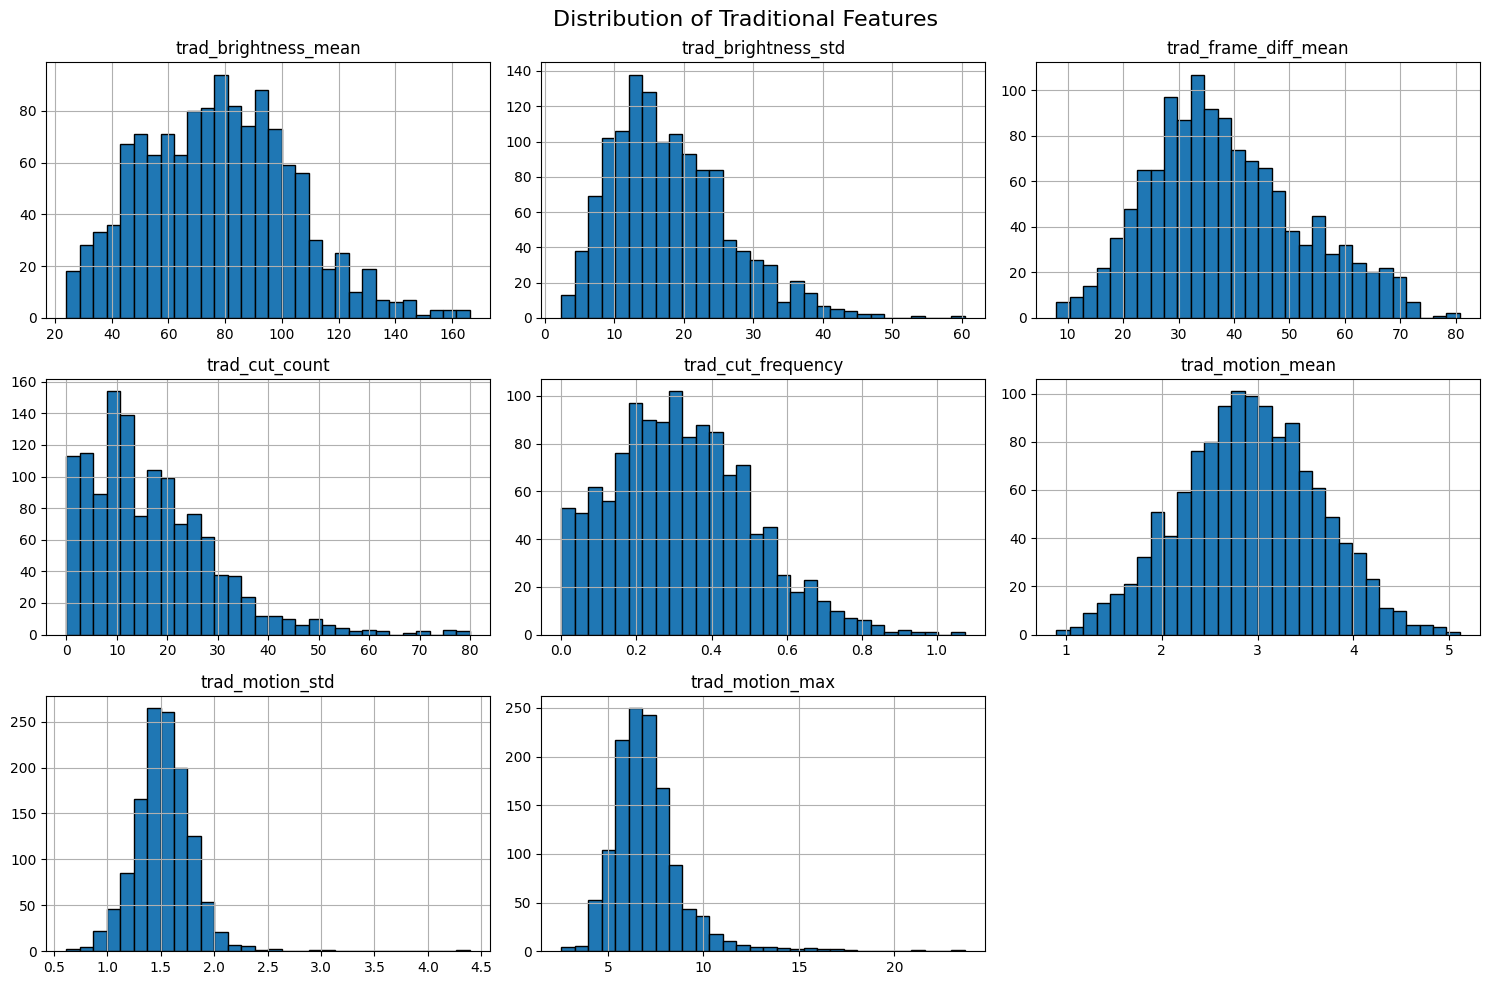

In [6]:
import matplotlib.pyplot as plt

trad_eda[trad_cols].hist(
    bins=30,
    figsize=(15, 10),
    edgecolor='black'
)

plt.suptitle(
    "Distribution of Traditional Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [7]:
# 컷 빈도가 0인 영상 확인
zero_cut = trad_eda[
    trad_eda['trad_cut_frequency'] == 0
]

print("전체 영상:", len(trad_eda))
print("컷 빈도 0인 영상:", len(zero_cut))
print(
    "비율:",
    round(len(zero_cut) / len(trad_eda) * 100, 2),
    "%"
)

# 컷 빈도 0인 영상의 정보 확인
display(
    zero_cut[
        [
            'video_id',
            'drama_name',
            'channel',
            'duration_sec',
            'trad_cut_count',
            'trad_cut_frequency'
        ]
    ].head(10)
)

전체 영상: 1270
컷 빈도 0인 영상: 38
비율: 2.99 %


,video_id,drama_name,channel,duration_sec,trad_cut_count,trad_cut_frequency
32,q8dEuDobU1s,소년시대,1분 샤샤샥,37.0,0,0.0
34,pk5re-OfxEo,소년시대,1분 샤샤샥,53.0,0,0.0
38,W5OfpQZT0Sw,소년시대,1분 샤샤샥,44.0,0,0.0
52,RgpJTaDdmMI,내 남편과 결혼해줘,1분 샤샤샥,36.0,0,0.0
56,TDf_qq6ASSk,내 남편과 결혼해줘,1분 샤샤샥,41.0,0,0.0
74,5pFQ8aq1haE,안나,K드릭스,49.0,0,0.0
227,MN7_qv3hfJM,이 사랑 통역 되나요?,드라마저장,62.0,0,0.0
229,CW4hqoVM2eM,이 사랑 통역 되나요?,드라마저장,57.0,0,0.0
261,3BzbfJ2zCPk,메이드 인 코리아2,드라마저장,57.0,0,0.0
339,fgXGLTm8R9g,부부의세계,1분드라마모음zip,45.0,0,0.0


In [8]:
# 채널별 전체 영상 수와 컷 빈도 0 비율
channel_zero = (
    trad_eda.assign(
        zero_cut=trad_eda['trad_cut_count'].eq(0)
    )
    .groupby('channel')
    .agg(
        total_videos=('video_id', 'count'),
        zero_cut_videos=('zero_cut', 'sum'),
        zero_cut_rate=('zero_cut', 'mean')
    )
)

channel_zero['zero_cut_rate'] *= 100

# 컷 빈도 0인 비율이 높은 채널 순
channel_zero = channel_zero.sort_values(
    'zero_cut_rate', ascending=False
)

display(channel_zero.round(2))

,total_videos,zero_cut_videos,zero_cut_rate
channel,,,
한드TV,130,11,8.46
1분 샤샤샥,61,5,8.20
드라마 한입,149,12,8.05
K드릭스,31,1,3.23
1분드라마모음zip,121,2,1.65
드라마저장,216,3,1.39
숏까네,485,4,0.82
아워무비,77,0,0.00


# STEP 4. Traditional 특징과 조회수 성과의 상관관계 분석

In [9]:
# Traditional 특징과 상대적 조회수 성과의 상관관계
trad_corr = (
    trad_eda[trad_cols + ['z_in_group']]
    .corr(method='spearman')['z_in_group']
    .drop('z_in_group')
    .sort_values(ascending=False)
)

print("Traditional 특징별 Spearman 상관계수")
display(trad_corr.to_frame(name='spearman_r'))

Traditional 특징별 Spearman 상관계수


,spearman_r
trad_frame_diff_mean,0.040009
trad_cut_count,0.038887
trad_motion_max,0.034957
trad_cut_frequency,0.027484
trad_motion_std,0.026815
trad_brightness_std,0.022773
trad_motion_mean,0.018029
trad_brightness_mean,0.015216


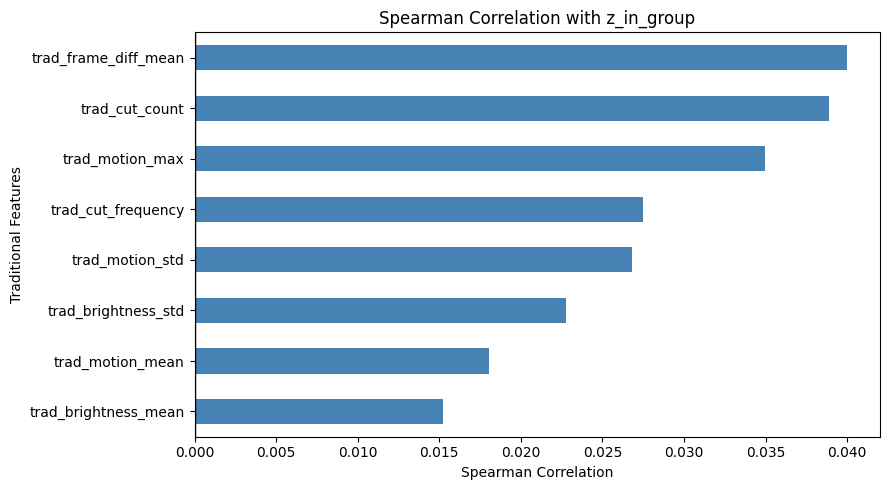

In [10]:
plt.figure(figsize=(9, 5))

trad_corr.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.axvline(0, color='black', linewidth=1)

plt.title(
    'Spearman Correlation with z_in_group'
)
plt.xlabel('Spearman Correlation')
plt.ylabel('Traditional Features')

plt.tight_layout()
plt.show()

# STEP 5. 영상 길이와 Traditional 특징의 상관관계

In [11]:
# 영상 길이와 Traditional 특징의 Spearman 상관관계
duration_corr = (
    trad_eda[trad_cols + ['duration_sec']]
    .corr(method='spearman')['duration_sec']
    .drop('duration_sec')
    .sort_values(ascending=False)
)

print("영상 길이와 Traditional 특징의 상관관계")
display(duration_corr.to_frame(name='spearman_r'))

영상 길이와 Traditional 특징의 상관관계


,spearman_r
trad_cut_count,0.662099
trad_brightness_std,0.380582
trad_motion_max,0.374613
trad_frame_diff_mean,0.354471
trad_cut_frequency,0.342179
trad_motion_mean,0.236678
trad_brightness_mean,0.113210
trad_motion_std,0.087194


# STEP 6. 영상 길이 통제 전후 상관계수 비교

In [12]:
# 1. 영상 길이와 특징, 성과를 순위로 변환
rank_df = trad_eda[
    trad_cols + ['duration_sec', 'z_in_group']
].rank()

# 2. 영상 길이의 순위 기준 표준화
x = rank_df['duration_sec']
x_center = x - x.mean()
x_var = (x_center ** 2).sum()

# 3. 성과에서 영상 길이 관계 제거
y = rank_df['z_in_group']
y_resid = y - (
    ((y - y.mean()) * x_center).sum() / x_var
) * x_center

# 4. 특징에서도 영상 길이 관계 제거
results = []

for col in trad_cols:
    f = rank_df[col]

    f_resid = f - (
        ((f - f.mean()) * x_center).sum() / x_var
    ) * x_center

    partial_r = f_resid.corr(y_resid)

    results.append({
        'feature': col,
        'before': trad_corr[col],
        'after_duration_control': partial_r
    })

partial_corr_df = pd.DataFrame(results).set_index('feature')

display(partial_corr_df.round(4))

,before,after_duration_control
feature,,
trad_brightness_mean,0.0152,0.0102
trad_brightness_std,0.0228,0.0060
trad_frame_diff_mean,0.0400,0.0257
trad_cut_count,0.0389,0.0120
trad_cut_frequency,0.0275,0.0128
trad_motion_mean,0.0180,0.0076
trad_motion_std,0.0268,0.0230
trad_motion_max,0.0350,0.0195


# STEP 7. 채널별 Traditional 특징과 성과의 관계

In [13]:
# 채널별 영상 수 확인
channel_counts = (
    trad_eda['channel']
    .value_counts()
)

print("전체 채널 수:", len(channel_counts))

print("\n채널별 영상 수:")
display(channel_counts.to_frame(name='video_count'))

# 30개 이상 영상이 있는 채널 선택
valid_channels = channel_counts[
    channel_counts >= 30
].index

print("\n분석 대상 채널 수:", len(valid_channels))
print("분석 대상 채널:", valid_channels.tolist())

전체 채널 수: 8

채널별 영상 수:


,video_count
channel,
숏까네,485
드라마저장,216
드라마 한입,149
한드TV,130
1분드라마모음zip,121
아워무비,77
1분 샤샤샥,61
K드릭스,31



분석 대상 채널 수: 8
분석 대상 채널: ['숏까네', '드라마저장', '드라마 한입', '한드TV', '1분드라마모음zip', '아워무비', '1분 샤샤샥', 'K드릭스']


# STEP 8. 채널×드라마별 컷 빈도 확인

In [14]:
# 채널 × 드라마별 컷 빈도 0 비율
drama_zero = (
    trad_eda.assign(
        zero_cut=trad_eda['trad_cut_count'].eq(0)
    )
    .groupby(['channel', 'drama_name'])
    .agg(
        total_videos=('video_id', 'count'),
        zero_cut_videos=('zero_cut', 'sum'),
        zero_cut_rate=('zero_cut', 'mean'),
        mean_cut_frequency=('trad_cut_frequency', 'mean')
    )
    .reset_index()
)

drama_zero['zero_cut_rate'] *= 100

# 컷 0인 영상이 많았던 두 채널 확인
result = drama_zero[
    drama_zero['channel'].isin(['한드TV', '드라마 한입'])
].sort_values(
    ['channel', 'zero_cut_videos'],
    ascending=[True, False]
)

display(result.round(3))

,channel,drama_name,total_videos,zero_cut_videos,zero_cut_rate,mean_cut_frequency
11,드라마 한입,미스터션샤인,149,12,8.054,0.204
55,한드TV,멜로가체질,25,6,24.000,0.205
57,한드TV,서른아홉,14,3,21.429,0.140
54,한드TV,날아올라라나비,15,1,6.667,0.151
60,한드TV,조선혼담공작소꽃파당,17,1,5.882,0.155
56,한드TV,부부의세계,15,0,0.000,0.242
58,한드TV,아파트,8,0,0.000,0.228
59,한드TV,이태원클라쓰,19,0,0.000,0.312
61,한드TV,킹더랜드,17,0,0.000,0.209


# STEP 9. 채널별 Traditional 특징과 상대적 조회수 성과의 관계 분석

## 채널별 Spearman 상관관계

In [15]:
# 채널별 Traditional 특징과 z_in_group의 상관관계

channel_corr_results = []

for channel, data in trad_eda.groupby('channel'):

    for feature in trad_cols:

        corr = data[feature].corr(
            data['z_in_group'],
            method='spearman'
        )

        channel_corr_results.append({
            'channel': channel,
            'n_videos': len(data),
            'feature': feature,
            'spearman_r': corr
        })

channel_corr_df = pd.DataFrame(channel_corr_results)

# 채널별 상관관계 표
channel_corr_table = channel_corr_df.pivot(
    index='channel',
    columns='feature',
    values='spearman_r'
)

display(channel_corr_table.round(3))

feature,trad_brightness_mean,trad_brightness_std,trad_cut_count,trad_cut_frequency,trad_frame_diff_mean,trad_motion_max,trad_motion_mean,trad_motion_std
channel,,,,,,,,
1분 샤샤샥,0.114,0.236,0.202,0.136,0.116,0.004,0.068,0.002
1분드라마모음zip,0.107,0.206,0.264,0.163,0.373,0.230,0.320,0.250
K드릭스,0.104,-0.029,-0.140,-0.057,0.012,-0.097,-0.207,0.065
드라마 한입,-0.145,-0.095,0.051,0.071,-0.017,-0.275,-0.099,-0.265
드라마저장,0.009,0.022,0.058,0.070,0.078,0.017,0.073,-0.026
숏까네,0.013,-0.022,-0.004,-0.021,0.016,0.069,0.033,0.058
아워무비,-0.160,0.092,0.366,0.035,-0.158,0.109,-0.372,0.172
한드TV,0.088,0.112,0.006,-0.004,0.192,0.102,0.120,0.095


## 컷 빈도와 성과의 관계부터 비교

In [16]:
# 채널별 컷 빈도와 성과의 관계
cut_channel_corr = channel_corr_df[
    channel_corr_df['feature'] == 'trad_cut_frequency'
].sort_values('spearman_r', ascending=False)

display(
    cut_channel_corr[
        ['channel', 'n_videos', 'spearman_r']
    ].round(3)
)

,channel,n_videos,spearman_r
12,1분드라마모음zip,121,0.163
4,1분 샤샤샥,61,0.136
28,드라마 한입,149,0.071
36,드라마저장,216,0.070
52,아워무비,77,0.035
60,한드TV,130,-0.004
44,숏까네,485,-0.021
20,K드릭스,31,-0.057


# STEP 10. 업로드 경과일과 Traditional 특징의 상관관계

In [17]:
# 업로드 경과일과 Traditional 특징의 Spearman 상관계수

days_corr = (
    trad_eda[trad_cols + ['days_since_upload', 'z_in_group']]
    .corr(method='spearman')['days_since_upload']
    .drop('days_since_upload')
    .sort_values(ascending=False)
)

print("업로드 경과일과 Traditional 특징 및 성과의 상관관계")
display(days_corr.to_frame(name='spearman_r').round(4))

업로드 경과일과 Traditional 특징 및 성과의 상관관계


,spearman_r
trad_motion_mean,0.4963
trad_frame_diff_mean,0.4466
trad_motion_max,0.3966
trad_brightness_std,0.3531
trad_cut_count,0.2755
trad_cut_frequency,0.2418
trad_motion_std,0.1807
trad_brightness_mean,0.0347
z_in_group,-0.0181


# STEP 11. 그룹 내 업로드 경과일과 상대적 성과

In [18]:
# 드라마×채널 그룹별 업로드 경과일과 성과의 관계
group_days_corr = (
    trad_eda.groupby('group')
    .apply(
        lambda x: x['days_since_upload'].corr(
            x['z_in_group'],
            method='spearman'
        ),
        include_groups=False
    )
    .dropna()
    .sort_values()
)

print("분석 가능한 그룹 수:", len(group_days_corr))

print("\n그룹별 상관계수 요약:")
display(group_days_corr.describe().round(3))

print("\n가장 음의 관계가 강한 그룹 5개:")
display(group_days_corr.head(5))

print("\n가장 양의 관계가 강한 그룹 5개:")
display(group_days_corr.tail(5))

분석 가능한 그룹 수: 62

그룹별 상관계수 요약:


,0
count,62.000
mean,0.147
std,0.358
min,-0.883
25%,-0.070
50%,0.169
75%,0.378
max,0.927



가장 음의 관계가 강한 그룹 5개:


,0
group,
악인전|숏까네,-0.883333
분리수거|숏까네,-0.771429
미스터션샤인|드라마 한입,-0.466442
슬기로운 의사생활|아워무비,-0.412917
안나|K드릭스,-0.339525



가장 양의 관계가 강한 그룹 5개:


,0
group,
아파트|숏까네,0.625385
나를 충전해줘|드라마저장,0.660606
계시록|숏까네,0.800000
상속자들|1분 샤샤샥,0.900000
"이재, 곧 죽습니다|1분 샤샤샥",0.927273


# STEP 12. 그룹·영상 길이·업로드 경과일 통제

In [19]:
import numpy as np

# 분석 변수
control_cols = [
    'duration_sec',
    'days_since_upload'
]

all_cols = trad_cols + control_cols + ['z_in_group']

# 그룹 내 평균 제거
within_df = trad_eda[all_cols] - (
    trad_eda.groupby('group')[all_cols].transform('mean')
)

# 통제변수 행렬
X = within_df[control_cols].to_numpy()

# 통제변수의 영향을 제거하는 함수
def residualize(y, X):
    coef = np.linalg.lstsq(X, y, rcond=None)[0]
    return y - X @ coef

# 성과 변수 잔차
y_resid = residualize(
    within_df['z_in_group'].to_numpy(), X
)

results = []

for feature in trad_cols:
    feature_resid = residualize(
        within_df[feature].to_numpy(), X
    )

    corr = np.corrcoef(
        feature_resid,
        y_resid
    )[0, 1]

    results.append({
        'feature': feature,
        'before': trad_corr[feature],
        'after_controls': corr
    })

control_results = pd.DataFrame(results).set_index('feature')

display(control_results.round(4))

,before,after_controls
feature,,
trad_brightness_mean,0.0152,0.0172
trad_brightness_std,0.0228,0.0096
trad_frame_diff_mean,0.0400,0.0738
trad_cut_count,0.0389,0.0331
trad_cut_frequency,0.0275,0.0319
trad_motion_mean,0.0180,0.0468
trad_motion_std,0.0268,0.0173
trad_motion_max,0.0350,0.0353
